# 🔬 Лабораторная работа 1. Пайплайн данных на PyTorch

## Цель работы

Научиться строить полноценный пайплайн данных для задачи классификации изображений:
- Создавать `Dataset` и `DataLoader`
- Настраивать аугментации для обучения и тестирования
- Визуализировать и анализировать данные
- Подготовить данные для передачи в нейронную сеть

---


---

##  Импорты

In [68]:
import torch
import torchvision
import torchvision.transforms as transforms
from torch.utils.data import Dataset, DataLoader
import numpy as np
import matplotlib.pyplot as plt
from collections import Counter
from PIL import Image
import os
import time

# Фиксируем seed для воспроизводимости
torch.manual_seed(42)
np.random.seed(42)

print("Все библиотеки импортированы успешно ✅")

Все библиотеки импортированы успешно ✅


---
## Задание 1. Загрузка и исследование датасета

### 1.1. Загрузите датасет CIFAR-10

Загрузите обучающую и тестовую выборки CIFAR-10 с преобразованием `ToTensor()`.

Выведите:
- Количество изображений в train и test
- Список классов
- Форму одного изображения (тензора)
- Минимальное и максимальное значение пикселей

In [69]:
# === ЗАДАНИЕ 1.1 ===

# Загрузите train и test датасеты CIFAR-10
# train_dataset = ...
# test_dataset = ...
basic_transform = transforms.ToTensor()

# Загружаем CIFAR-10 (train)
train_dataset = torchvision.datasets.CIFAR10(
    root='../data',
    train=True,
    download=True,
    transform=basic_transform
)

# Загружаем CIFAR-10 (test)
test_dataset = torchvision.datasets.CIFAR10(
    root='../data',
    train=False,
    download=True,
    transform=basic_transform
)

# Выведите информацию о датасете
train_counts = len(train_dataset.targets)
test_counts = len(test_dataset.targets)
print(f"Количество изображений train: {train_counts} \nКоличество изображений test: {test_counts}")

list_of_classes = train_dataset.classes
print(f"Список классов {list_of_classes}")

image, label = train_dataset[0]
print(f"Форма одного изображения (тензора): {image.shape}")

print("Минимальное значение пикселя:", image.min().item())
print("Максимальное значение пикселя:", image.max().item())

Количество изображений train: 50000 
Количество изображений test: 10000
Список классов ['airplane', 'automobile', 'bird', 'cat', 'deer', 'dog', 'frog', 'horse', 'ship', 'truck']
Форма одного изображения (тензора): torch.Size([3, 32, 32])
Минимальное значение пикселя: 0.0
Максимальное значение пикселя: 1.0


### 1.2. Визуализируйте по 3 изображения из каждого класса

Создайте сетку 10×3 (10 классов × 3 примера). Подпишите каждую строку названием класса.

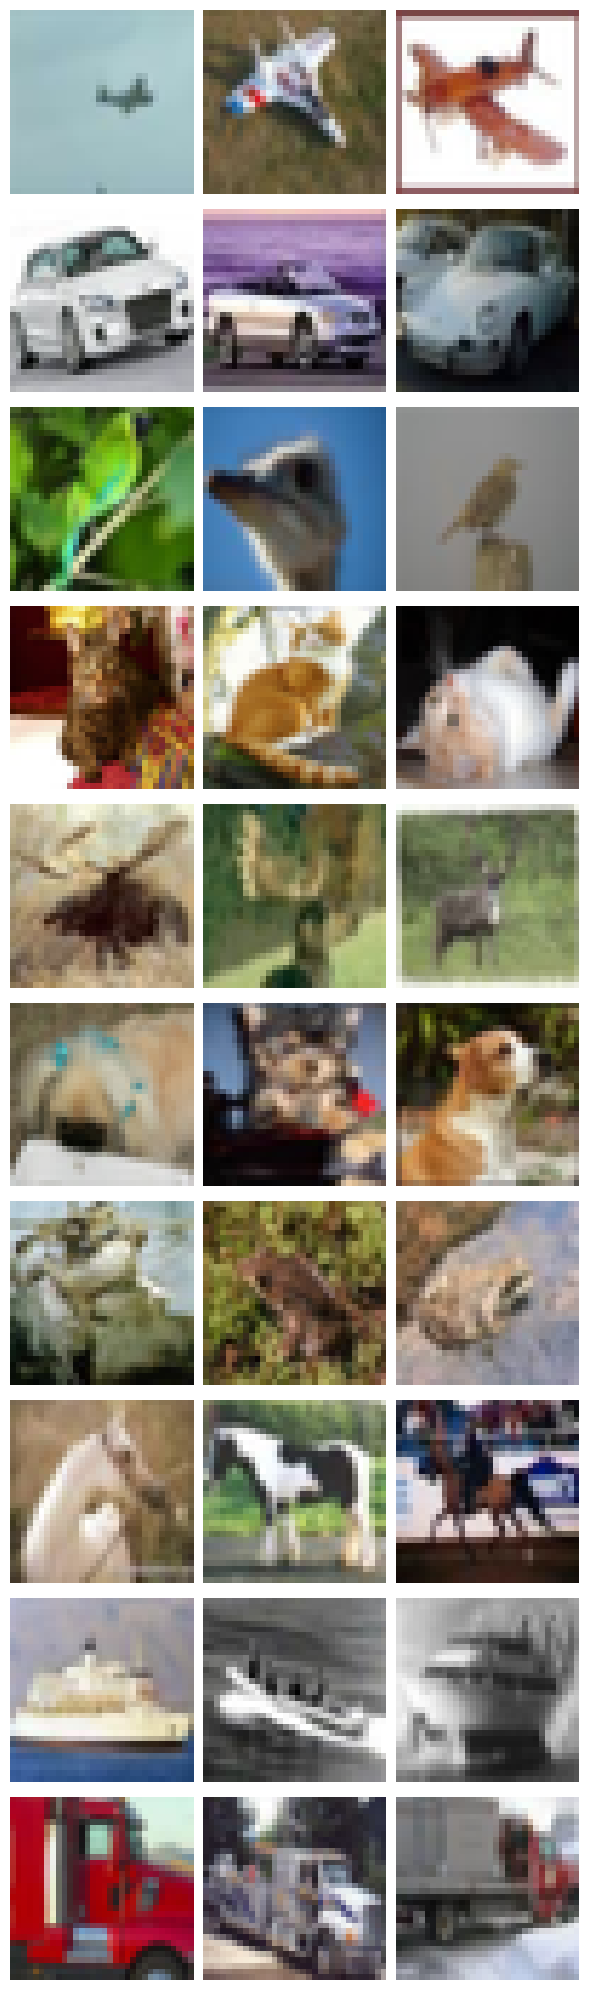

In [70]:
# === ЗАДАНИЕ 1.2 ===
import random

def show_samples_per_class(dataset, samples_per_class=3, figsize=(10, 10)):
    """
    Визуализирует samples_per_class изображений из каждого класса.

    Args:
        dataset: torchvision dataset
        samples_per_class: количество примеров на класс
    """
    classes = dataset.classes
    n_classes = len(classes)

    fig, axes = plt.subplots(n_classes, samples_per_class, figsize=figsize)


    targets = dataset.targets

    for row_indx, class_name in enumerate(classes):
        # 1. Индексы изображений класса
        class_indices = [i for i, target in enumerate(targets) if target == row_indx]

        # 2. Случайные примеры
        selected_indices = random.sample(class_indices, min(samples_per_class, len(class_indices)))

        for col_indx, idx in enumerate(selected_indices):
            img, label = dataset[idx]

            img = img.permute(1, 2, 0).numpy()

            ax = axes[row_indx, col_indx]
            ax.imshow(img)
            ax.axis('off')


    plt.tight_layout()
    plt.show()

    # Реализуйте функцию
    # Подсказка:
    # 1. Для каждого класса найдите индексы изображений этого класса
    # 2. Выберите случайные samples_per_class индексов
    # 3. Создайте plt.subplots(n_classes, samples_per_class, ...)
    # 4. Отобразите изображения
    pass

show_samples_per_class(train_dataset, figsize=(6, 20))

### 1.3. Постройте гистограмму распределения значений пикселей

Для первых 1000 изображений постройте гистограмму значений пикселей — общую и по каждому каналу (R, G, B) отдельно.

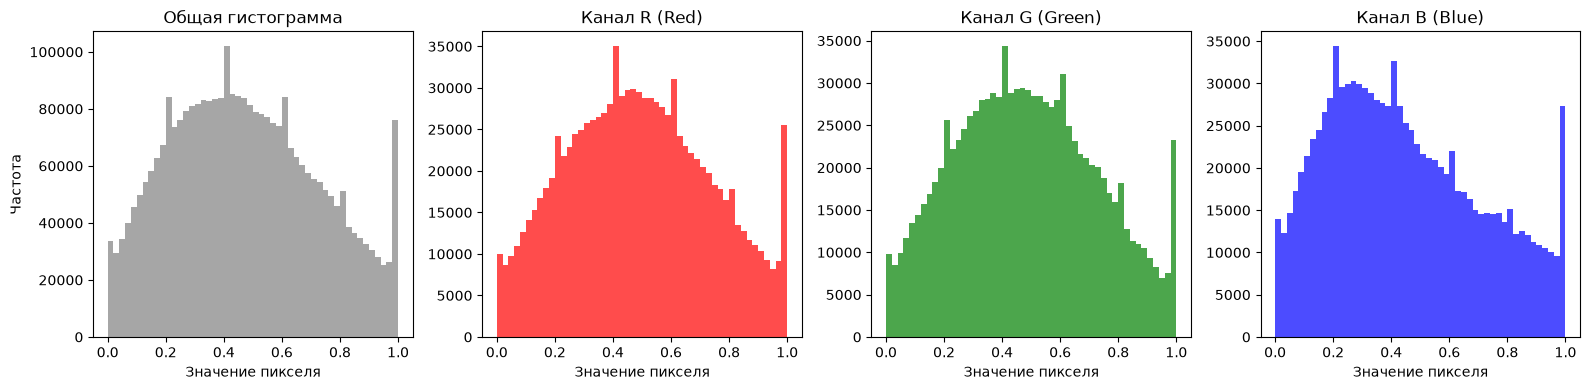

In [71]:
# === ЗАДАНИЕ 1.3 ===

n = 1000

r_pixel, g_pixel, b_pixel = [], [], []

for i in range(n):
    img, label = train_dataset[i]

    img = img.permute(1, 2, 0).numpy()

    r_pixel.extend(img[:, :, 0].flatten()) # флатен превращает в вектор
    g_pixel.extend(img[:, :, 1].flatten()) # экстенденд склеивает с предыдущемы
    b_pixel.extend(img[:, :, 2].flatten())

r_pixel = np.array(r_pixel)
g_pixel = np.array(g_pixel)
b_pixel = np.array(b_pixel)

all_pixels = np.concatenate([r_pixel, g_pixel, b_pixel])

fig, axes = plt.subplots(1, 4, figsize=(16, 4))

axes[0].hist(all_pixels, bins=50, color='gray', alpha=0.7)
axes[0].set_title('Общая гистограмма')
axes[0].set_xlabel('Значение пикселя')
axes[0].set_ylabel('Частота')

axes[1].hist(r_pixel, bins=50, color='red', alpha=0.7)
axes[1].set_title('Канал R (Red)')
axes[1].set_xlabel('Значение пикселя')

axes[2].hist(g_pixel, bins=50, color='green', alpha=0.7)
axes[2].set_title('Канал G (Green)')
axes[2].set_xlabel('Значение пикселя')

axes[3].hist(b_pixel, bins=50, color='blue', alpha=0.7)
axes[3].set_title('Канал B (Blue)')
axes[3].set_xlabel('Значение пикселя')

plt.tight_layout()
plt.show()

---
## Задание 2. DataLoader и визуализация батчей

### 2.1. Создайте DataLoader

Создайте DataLoader для обучающей выборки со следующими параметрами:
- `batch_size=64`
- `shuffle=True`
- `num_workers=2` (или 0 на Windows)

Выведите:
- Количество батчей
- Форму одного батча (images и labels)

In [72]:
# === ЗАДАНИЕ 2.1 ===

# Создайте DataLoader
# train_loader = DataLoader(...)

train_dataloader = DataLoader(train_dataset, batch_size=64, shuffle=True, num_workers=2)
test_dataloader = DataLoader(test_dataset, batch_size=64, shuffle=True, num_workers=2)

# Получите один батч и выведите информацию
# images, labels = next(iter(train_loader))
images, labels = next(iter(train_dataloader))
# print(f"Форма батча изображений: {images.shape}")  # Ожидание: [64, 3, 32, 32]
print(f"Форма батча изображений: {images.shape}")
# print(f"Форма батча меток: {labels.shape}")         # Ожидание: [64]
print(f"Форма батча меток: {labels.shape}")
# print(f"Количество батчей: {len(train_loader)}")
print(f"Количество батчей: {len(train_dataloader)}")


Форма батча изображений: torch.Size([64, 3, 32, 32])
Форма батча меток: torch.Size([64])
Количество батчей: 782


### 2.2. Визуализируйте один батч

Используйте `torchvision.utils.make_grid()` для создания сетки из одного батча.

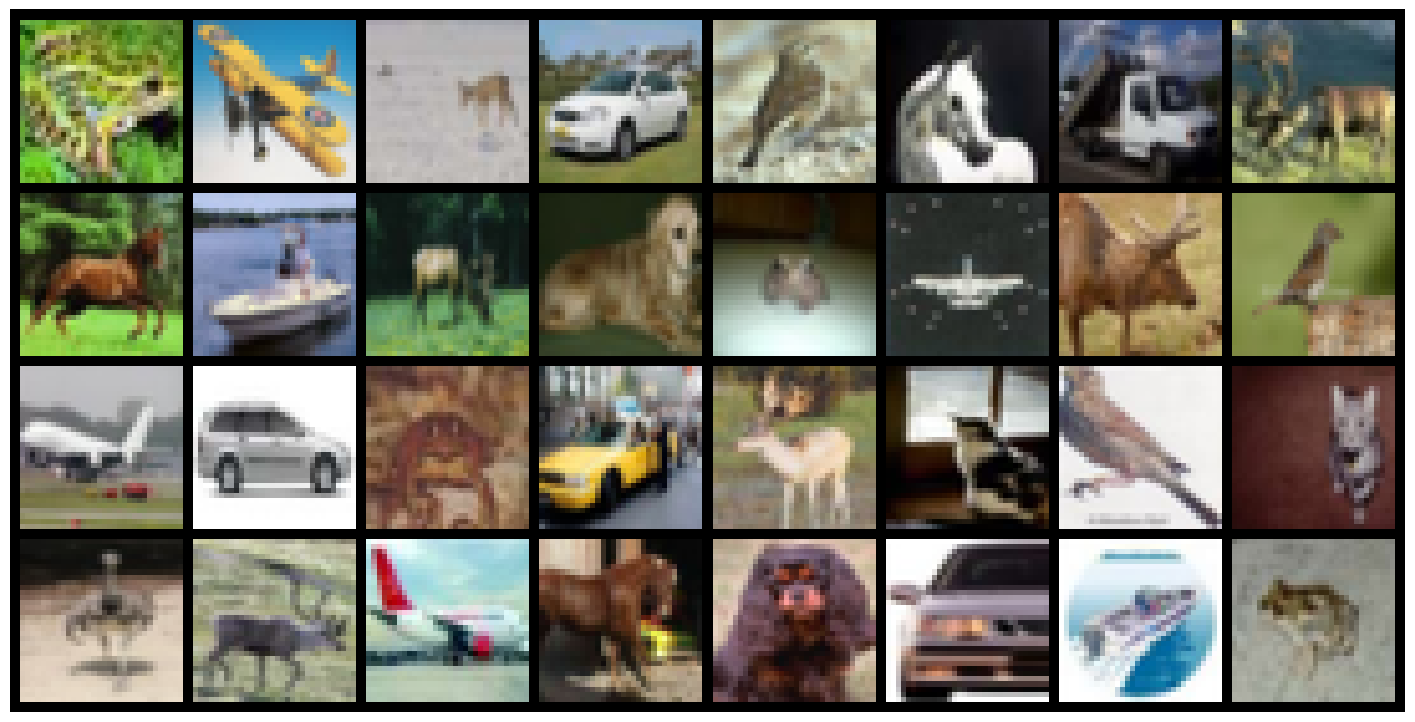

In [73]:
# === ЗАДАНИЕ 2.2 ===

def show_batch(images, labels, classes, max_images=32):
    """
    Визуализирует батч изображений в виде сетки.

    Args:
        images: тензор (B, C, H, W)
        labels: тензор (B,)
        classes: список названий классов
        max_images: максимальное количество изображений для отображения
    """
    # Реализуйте функцию
    # Подсказка:
    # 1. Возьмите первые max_images изображений
    # 2. Используйте torchvision.utils.make_grid(images[:max_images], nrow=8)
    grid = torchvision.utils.make_grid(images[:max_images],nrow=8)
    # 3. Конвертируйте результат для matplotlib: grid.permute(1, 2, 0)
    grid = grid.permute(1,2,0)
    # 4. Отобразите с plt.imshow()
    plt.figure(figsize=(18,20))
    plt.imshow(grid)
    plt.axis('off')
    plt.show()
    pass

show_batch(images, labels, train_dataset.classes)

### 2.3. Замерьте скорость загрузки данных

Сравните время итерации по всему DataLoader с разными параметрами:
- `batch_size`: 16, 64, 256
- `num_workers`: 0, 2, 4

Результат оформите в виде таблицы.

In [74]:
# === ЗАДАНИЕ 2.3 ===

def benchmark_dataloader(dataset, batch_size, num_workers, num_batches=50):
    """
    Замеряет среднее время загрузки батча.

    Returns:
        float: среднее время на батч в миллисекундах
    """
    loader = DataLoader(
        dataset, batch_size=batch_size,
        shuffle=True, num_workers=num_workers
    )

    start = time.time()
    for i, (images, labels) in enumerate(loader):
        if i >= num_batches:
            break
        _ = images.shape  # Минимальная операция
    elapsed = time.time() - start

    return (elapsed / min(num_batches, len(loader))) * 1000

# Протестируйте разные комбинации batch_size и num_workers
# Оформите результаты в таблицу
# Подсказка: на Windows num_workers > 0 может не работать

print("batch_size | num_workers | мс/батч")
print("-" * 40)
for bs in [16, 64, 256]:
     for nw in [0, 2, 4]:
        ms = benchmark_dataloader(train_dataset, bs, nw)
        print(f"{bs:>10} | {nw:>11} | {ms:.2f}")

batch_size | num_workers | мс/батч
----------------------------------------
        16 |           0 | 2.05
        16 |           2 | 223.11
        16 |           4 | 445.20
        64 |           0 | 8.37
        64 |           2 | 221.86
        64 |           4 | 447.95
       256 |           0 | 31.13
       256 |           2 | 233.01
       256 |           4 | 436.19


---
## Задание 3. Пайплайн аугментаций

### 3.1. Создайте два пайплайна

**Train-пайплайн** (с аугментациями):
1. `RandomHorizontalFlip(p=0.5)`
2. `RandomCrop(32, padding=4)`
3. `ColorJitter(brightness=0.2, contrast=0.2, saturation=0.2)`
4. `ToTensor()`
5. `Normalize(mean, std)` — используйте значения, вычисленные для CIFAR-10

**Test-пайплайн** (без аугментаций):
1. `ToTensor()`
2. `Normalize(mean, std)`

Создайте обновлённые датасеты и DataLoader'ы.

In [75]:
# === ЗАДАНИЕ 3.1 ===

# Статистика CIFAR-10
CIFAR10_MEAN = (0.4914, 0.4822, 0.4465)
CIFAR10_STD = (0.2470, 0.2435, 0.2616)

# Создайте train_transform
# train_transform = transforms.Compose([...])
train_transform = transforms.Compose([
transforms.RandomHorizontalFlip(p=0.5),
transforms.RandomCrop(32,padding=4),
transforms.ColorJitter(brightness=0.2, contrast=0.3, saturation=0.2),
transforms.ToTensor(),
transforms.Normalize(mean=CIFAR10_MEAN,std=CIFAR10_STD)
])

# Создайте test_transform
# test_transform = transforms.Compose([...])
test_transform = transforms.Compose([
transforms.ToTensor(),
transforms.Normalize(mean=CIFAR10_MEAN,std=CIFAR10_STD)
])

# Создайте датасеты с новыми трансформами
# train_dataset_aug = torchvision.datasets.CIFAR10(
#     root='./data', train=True, download=False, transform=train_transform
# )
train_dataset_aug = torchvision.datasets.CIFAR10(
root='../data', train=True, download=False, transform=train_transform
)

test_dataset_new_trans = torchvision.datasets.CIFAR10(
root='../data', train=False, download=False, transform=test_transform
)

# Создайте DataLoader'ы
# train_loader_aug = DataLoader(...)
# test_loader = DataLoader(...)
train_loader_aug = DataLoader(train_dataset_aug, batch_size=64, shuffle=True, num_workers=2)
test_loader = DataLoader(test_dataset_new_trans, batch_size=64, shuffle=True, num_workers=2)



### 3.2. Визуальное сравнение: с аугментацией и без

Возьмите одно и то же изображение (по индексу) и покажите:
- Верхний ряд: 8 версий **без** аугментации (будут одинаковые)
- Нижний ряд: 8 версий **с** аугментацией (будут разные)

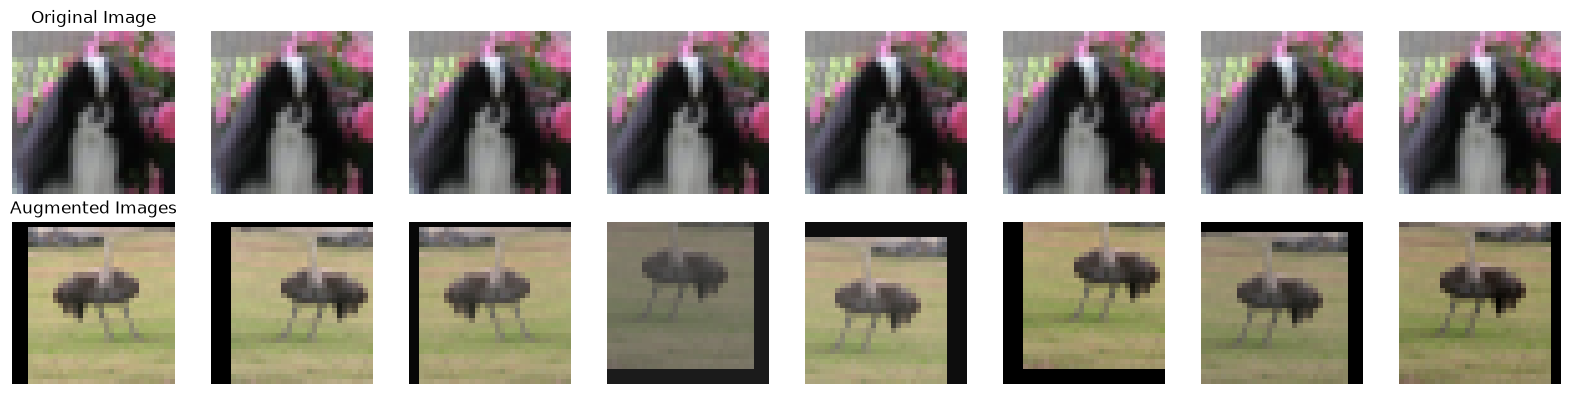

In [76]:
# === ЗАДАНИЕ 3.2 ===

def compare_augmentations(dataset_no_aug, dataset_aug, idx, n_versions=8):
    """
    Показывает n_versions версий одного изображения с и без аугментаций.

    Важно: для денормализации используйте формулу:
        img = img * std + mean
    """
    # Реализуйте функцию
    # Подсказка:
    # 1. Для денормализации создайте обратное преобразование
    img_no_aug, label = dataset_no_aug[idx]

    # Денормализация и подготовка для matplotlib
    mean = torch.tensor(CIFAR10_MEAN).view(3, 1, 1)
    std = torch.tensor(CIFAR10_STD).view(3, 1, 1)

    # 2. fig, axes = plt.subplots(2, n_versions, ...)
    fig, axes = plt.subplots(2, n_versions, figsize=(n_versions*2, 4))

    # 3. Верхний ряд: dataset_no_aug[idx] повторить n_versions раз
    for i in range(n_versions):
        img_no_aug, label_no_aug = dataset_no_aug[idx]
        img_no_aug = img_no_aug * std + mean
        img_no_aug = img_no_aug.permute(1, 2, 0).numpy().clip(0, 1)
        axes[0, i].imshow(img_no_aug)
        axes[0, i].axis('off')

    # 4. Нижний ряд: dataset_aug[idx] вызвать n_versions раз
    #    (аугментации случайные → каждый раз разный результат)
    for i in range(n_versions):
        img_aug, label_aug = dataset_aug[idx]
        img_aug = img_aug * std + mean  # Денормализация
        img_aug = img_aug.permute(1, 2, 0).numpy().clip(0, 1)
        axes[1, i].imshow(img_aug)
        axes[1, i].axis('off')

    axes[0, 0].set_title(f"Original Image")
    axes[1, 0].set_title(f"Augmented Images")
    plt.tight_layout()
    plt.show()

compare_augmentations(test_dataset_new_trans, train_dataset_aug, idx=42)

---
## Задание 4. Кастомный Dataset

### 4.1. Создайте свой класс Dataset

Реализуйте класс `ColorShapesDataset`, который **генерирует синтетические изображения** с простыми фигурами.

Требования:
- 3 класса: `circle` (круг), `square` (квадрат), `triangle` (треугольник)
- Размер изображения: 64×64
- Случайные цвета фигур и фона
- Случайный размер и положение фигур
- Поддержка `transform`

Этот Dataset должен наследоваться от `torch.utils.data.Dataset` и реализовывать методы `__len__` и `__getitem__`.

In [77]:
# === ЗАДАНИЕ 4.1 ===

class ColorShapesDataset(Dataset):
    """
    Синтетический датасет с цветными геометрическими фигурами.

    Классы:
        0 - circle (круг)
        1 - square (квадрат)
        2 - triangle (треугольник)
    """

    classes = ['circle', 'square', 'triangle']

    def __init__(self, num_samples=1000, image_size=64, transform=None):
        """
        Args:
            num_samples: количество изображений в датасете
            image_size: размер изображений (image_size × image_size)
            transform: преобразования torchvision
        """
        self.num_samples = num_samples
        self.image_size = image_size
        self.transform = transform

        # Генерируем метки заранее (равномерно по классам)
        self.labels = [i % len(self.classes) for i in range(num_samples)]
        np.random.shuffle(self.labels)
        self.targets = self.labels

    def __len__(self):
        return self.num_samples

    def _generate_image(self, label):
        """
        Генерирует изображение с фигурой заданного класса.

        Returns:
            PIL.Image: сгенерированное изображение
        """
        # Реализуйте генерацию изображений
        # Подсказка:
        # 1. Создайте массив numpy (image_size, image_size, 3) с случайным фоном
        img = np.random.randint(0, 100, (self.image_size, self.image_size, 3), dtype=np.uint8)

        # Случайный цвет фигуры (яркий)
        color = np.random.randint(150, 256, 3)

        # Случайный центр и размер
        size = np.random.randint(self.image_size // 6, self.image_size // 3)
        margin = size + 2
        cx = np.random.randint(margin, self.image_size - margin)
        cy = np.random.randint(margin, self.image_size - margin)

        y_indices, x_indices = np.ogrid[:self.image_size, :self.image_size]

        # 2. В зависимости от label нарисуйте фигуру:
        #    - circle: используйте формулу (x-cx)^2 + (y-cy)^2 <= r^2
        if label == 0:
            mask = (x_indices - cx) ** 2 + (y_indices - cy) ** 2 <= size ** 2
            img[mask] = color

        #    - square: простое заполнение прямоугольной области
        elif label == 1:
            x1 = max(0, cx - size)
            x2 = min(self.image_size, cx + size)
            y1 = max(0, cy - size)
            y2 = min(self.image_size, cy + size)
            img[y1:y2, x1:x2] = color
        #    - triangle: используйте формулу для точки внутри треугольника
        elif label == 2:
            x_top, y_top = cx, cy - size
            x_left, y_left = cx - size, cy + size
            x_right, y_right = cx + size, cy + size

            # Проверка принадлежности точки треугольнику через барицентрические координаты или полуплоскости
            # Используем условие знака векторного произведения для полуплоскостей
            def sign(p1_x, p1_y, p2_x, p2_y, p3_x, p3_y):
                return (p1_x - p3_x) * (p2_y - p3_y) - (p2_x - p3_x) * (p1_y - p3_y)

            b1 = sign(x_indices, y_indices, x_top, y_top, x_left, y_left) < 0
            b2 = sign(x_indices, y_indices, x_left, y_left, x_right, y_right) < 0
            b3 = sign(x_indices, y_indices, x_right, y_right, x_top, y_top) < 0

            mask = (b1 == b2) & (b2 == b3)
            img[mask] = color
        # 3. Конвертируйте в PIL Image

        # Добавьте сюда отрисовку фигуры в зависимости от label
        # label == 0: circle
        # label == 1: square
        # label == 2: triangle

        return Image.fromarray(img)

    def __getitem__(self, idx):
        label = self.labels[idx]

        # Фиксируем seed для воспроизводимости
        rng_state = np.random.get_state()
        np.random.seed(idx)
        image = self._generate_image(label)
        np.random.set_state(rng_state)

        if self.transform:
            image = self.transform(image)

        return image, label

### 4.2. Протестируйте ваш Dataset

1. Создайте экземпляр `ColorShapesDataset` с 300 изображениями
2. Визуализируйте по 5 изображений каждого класса
3. Оберните в DataLoader и выведите один батч через `make_grid`

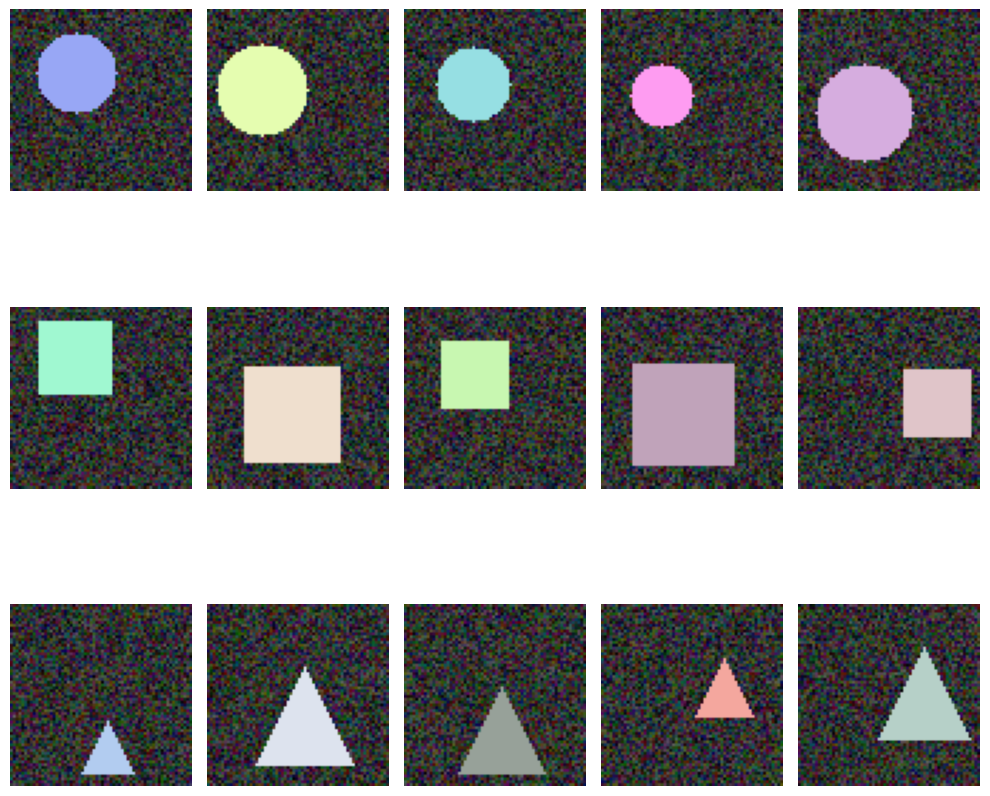

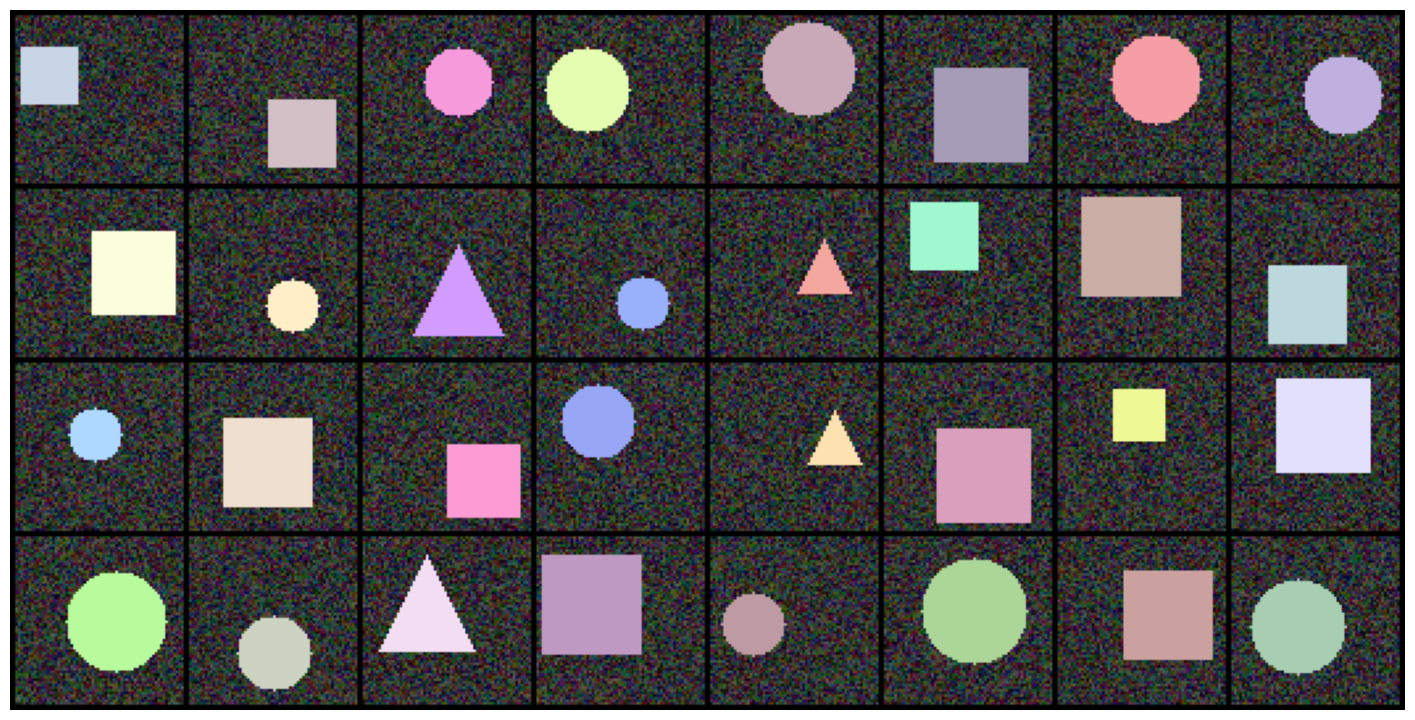

In [78]:
# === ЗАДАНИЕ 4.2 ===

# Создайте датасет
shapes_dataset = ColorShapesDataset(num_samples=300, transform=transforms.ToTensor())

# Визуализируйте примеры
show_samples_per_class(shapes_dataset, samples_per_class=5, figsize=(10, 10))

# Создайте DataLoader и покажите батч
train_dataloader_fig = DataLoader(shapes_dataset, batch_size=64, shuffle=True, num_workers=0)
images, labels = next(iter(train_dataloader_fig))
show_batch(images, labels, shapes_dataset.classes, max_images=32)


---
## Задание 5. Анализ влияния аугментаций

### Исследование

Проведите эксперимент: как аугментации меняют статистику датасета?

1. Возьмите 500 изображений из CIFAR-10
2. Примените к каждому 10 разных аугментаций (всего 5000 изображений)
3. Для каждого типа аугментации вычислите:
   - Среднее и std значений пикселей
   - Энтропию изображений (мера информативности)
4. Постройте сравнительные графики

Типы аугментаций для сравнения:
- Без аугментации (baseline)
- Только горизонтальное отражение
- Только случайный кроп
- Только ColorJitter
- Агрессивная аугментация (всё вместе + поворот + размытие)

### Вопросы для анализа

Ответьте в текстовой ячейке:
1. Какая аугментация сильнее всего меняет распределение пикселей?
2. Какие аугментации безопасны для CIFAR-10, а какие могут навредить? (Подсказка: подумайте, что произойдёт с автомобилем при вертикальном отражении)
3. Почему нормализацию нужно выполнять ПОСЛЕ аугментаций, а не до?

In [79]:
!pip install scipy pandas

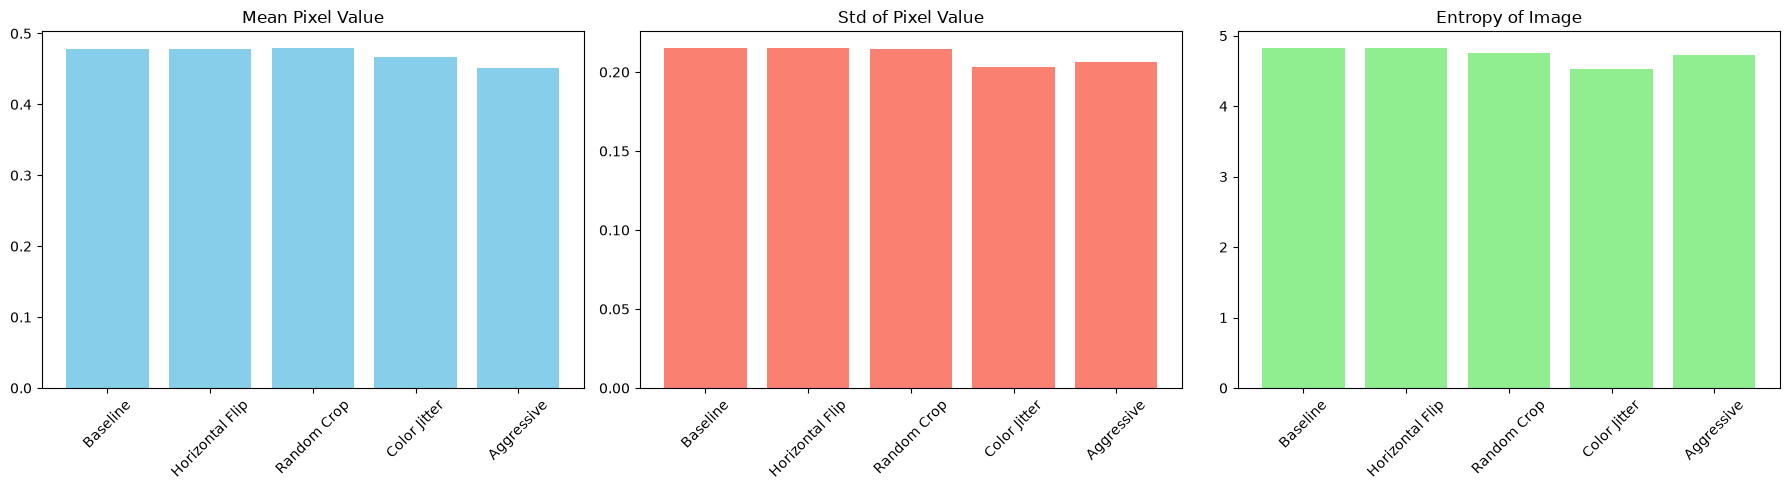

In [80]:
# === ЗАДАНИЕ 5 (БОНУС) ===

from scipy.stats import entropy
import pandas as pd

def compute_image_entropy(image_tensor):
    """Вычисляет энтропию изображения."""
    # Конвертируем в grayscale
    gray = image_tensor.mean(dim=0)  # (H, W)
    # Гистограмма значений
    hist = torch.histc(gray, bins=256, min=0, max=1)
    # Нормализуем
    hist = hist / hist.sum()
    # Убираем нули
    hist = hist[hist > 0]
    return entropy(hist.numpy())

# Проведите эксперимент
base_dataset = torchvision.datasets.CIFAR10(
    root='../data', train=True, download=False)
indices = np.random.choice(len(base_dataset), size=500, replace=False)
subset_images = torch.utils.data.Subset(base_dataset, indices)

augmentations = {
    "Baseline": transforms.Compose([
        transforms.Resize((32, 32)),
        transforms.ToTensor()
    ]),
    "Horizontal Flip": transforms.Compose([
        transforms.RandomHorizontalFlip(p=1.0),
        transforms.ToTensor()
    ]),
    "Random Crop": transforms.Compose([
        transforms.Pad(4, padding_mode='edge'),
        transforms.RandomCrop(32),
        transforms.ToTensor()
    ]),
    "Color Jitter": transforms.Compose([
        transforms.ColorJitter(brightness=0.4, contrast=0.4, saturation=0.4, hue=0.1),
        transforms.ToTensor()
    ]),
    "Aggressive": transforms.Compose([
        transforms.RandomHorizontalFlip(p=0.5),
        transforms.RandomRotation(15),
        transforms.ColorJitter(brightness=0.3, contrast=0.3, saturation=0.3),
        transforms.GaussianBlur(kernel_size=3),
        transforms.ToTensor()
    ])
}

results = []
for aug_name, aug_transform in augmentations.items():
    means = []
    stds = []
    entropies = []
    for img, _ in subset_images:
        img_aug = aug_transform(img)
        means.append(img_aug.mean().item())
        stds.append(img_aug.std().item())
        entropies.append(compute_image_entropy(img_aug))
    results.append({
        "Augmentation": aug_name,
        "Mean": np.mean(means),
        "Std": np.mean(stds),
        "Entropy": np.mean(entropies)
    })

# Постройте графики
df_results = pd.DataFrame(results)
df_results

names = df_results['Augmentation']
means = df_results['Mean']
stds = df_results['Std']
entropies = df_results['Entropy']

fig, axes = plt.subplots(1, 3, figsize=(18, 5))

axes[0].bar(names, means, color='skyblue')
axes[0].set_title('Mean Pixel Value')
axes[0].tick_params(axis='x', rotation=45)

axes[1].bar(names, stds, color='salmon')
axes[1].set_title('Std of Pixel Value')
axes[1].tick_params(axis='x', rotation=45)

axes[2].bar(names, entropies, color='lightgreen')
axes[2].set_title('Entropy of Image')
axes[2].tick_params(axis='x', rotation=45)

plt.tight_layout()
plt.show()


1. **Какая аугментация сильнее всего меняет распределение пикселей?**
Сильнее всего распределение пикселей меняют `ColorJitter` и `Aggressive`. Это отлично видно по построенным графикам у них заметнее всего проседают показатели стандартного отклонения и энтропии. Данные преобразования напрямую влияют на яркость, контрастность, насыщенность и цвета пикселей, в то время как горизонтальное отражение или случайный кроп практически не меняют статистику распределения яркости и информативность изображения.
2. **Какие аугментации безопасны для CIFAR-10, а какие могут навредить?**
* **Безопасные:** Горизонтальный флип  и случайный кроп. Объекты в датасете CIFAR-10  могут быть развернуты в разные стороны, а небольшой сдвиг рамки при кропе помогает модели учиться инвариантности к положению объекта без потери его смысла.
* **Вредные:** Вертикальный флип  или чрезмерно агрессивные искажения. Например, перевернутые вверх тормашками автомобили или животные противоречат реальному физическому миру, из-за чего модель начнет заучивать некорректные признаки. Сильное размытие (GaussianBlur) на крошечных картинках 32×32 пикселя полностью затирает мелкие детали, делая объект нераспознаваемым даже для человека.

3. **Почему нормализацию нужно выполнять ПОСЛЕ аугментаций, а не до?**
Нормализация переводит значения пикселей в диапазон *[-1,1]*. Если выполнить её *до* аугментаций:
* Библиотеки трансформаций будут ожидать стандартные неотрицательные изображения в диапазоне от 0 до 1 или 0 до 255. Отрицательные значения приведут к некорректной заливке фона и артефактам по краям.
* Попиксельные цветовые преобразования рассчитаны на работу с исходной яркостью в положительном диапазоне. Поэтому стандартный пайплайн всегда строится так сначала случайные геометрические и цветовые аугментации, а в самом конце — перевод в тензор и нормализация.


---

## Полезные ссылки

- [PyTorch: Dataset и DataLoader](https://pytorch.org/tutorials/beginner/basics/data_tutorial.html)
- [torchvision.transforms](https://pytorch.org/vision/stable/transforms.html)
- [torchvision.datasets](https://pytorch.org/vision/stable/datasets.html)
- [torchvision.utils.make_grid](https://pytorch.org/vision/stable/generated/torchvision.utils.make_grid.html)